In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 10  # 节点数量
#生成一个包含 N 个在 [0, 1) 区间内均匀分布的随机数的数组 * 0.1
rho = np.random.rand(N) * 0.1 

rho

array([0.09618389, 0.06865304, 0.01165019, 0.02609796, 0.04549258,
       0.03532251, 0.09480193, 0.09226245, 0.01328015, 0.01703204])

In [5]:
steps = 200  # 时间步数
rho_history = np.zeros((steps, N)) # 生成一个形状为 (steps, N) 的二维数组（矩阵）
rho_history

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [8]:
N = 10  # 节点数量
P = 1000  # 总人口
n = np.random.randint(50, 150, size=N)  # 每个节点的初始人口
np.sum(n)
# n = n / np.sum(n) * P  # 调整总人口数量


856

[[ 0.  9.  0.  8.  8.  0.  0.  0.  2.  0.]
 [ 9.  0.  0.  0.  0.  6.  7.  7.  0.  0.]
 [ 0.  0.  0.  8.  3.  0.  9.  0.  0. 10.]
 [ 8.  0.  8.  0.  6.  7.  0.  0.  0. 10.]
 [ 8.  0.  3.  6.  0.  0.  0.  3.  0.  9.]
 [ 0.  6.  0.  7.  0.  0.  0.  0.  0.  0.]
 [ 0.  7.  9.  0.  0.  0.  0.  0.  2.  8.]
 [ 0.  7.  0.  0.  3.  0.  0.  0.  6.  0.]
 [ 2.  0.  0.  0.  0.  0.  2.  6.  0.  7.]
 [ 0.  0. 10. 10.  9.  0.  8.  0.  7.  0.]]
[[0.         0.33333333 0.         0.2962963  0.2962963  0.
  0.         0.         0.07407407 0.        ]
 [0.31034483 0.         0.         0.         0.         0.20689655
  0.24137931 0.24137931 0.         0.        ]
 [0.         0.         0.         0.26666667 0.1        0.
  0.3        0.         0.         0.33333333]
 [0.20512821 0.         0.20512821 0.         0.15384615 0.17948718
  0.         0.         0.         0.25641026]
 [0.27586207 0.         0.10344828 0.20689655 0.         0.
  0.         0.10344828 0.         0.31034483]
 [0.         0.461

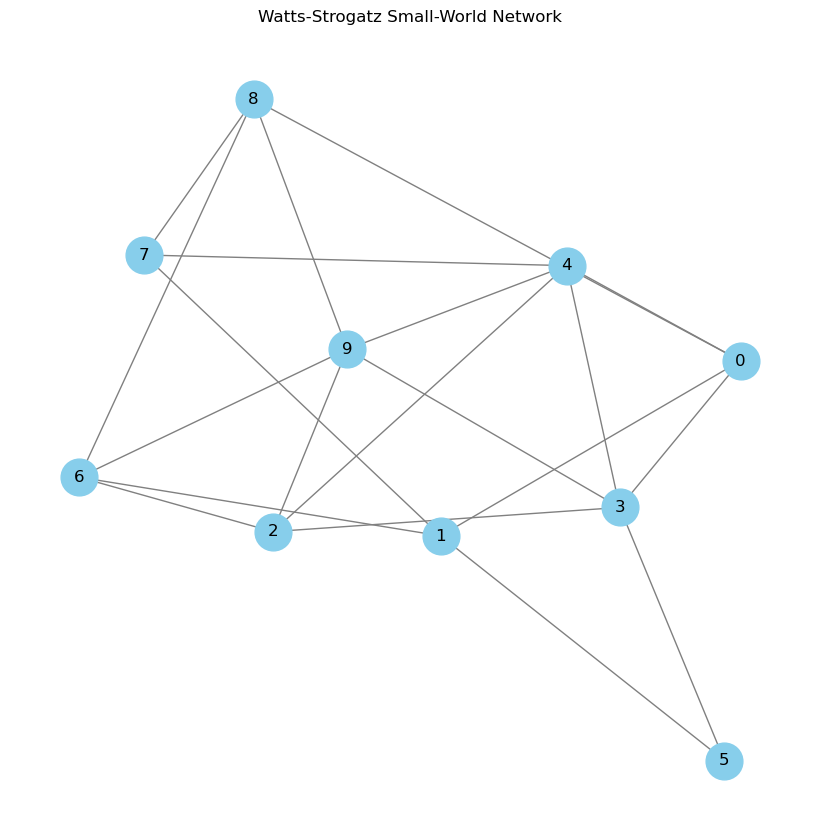

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
# 定义节点数和每个节点的邻居数
N = 10  # 节点总数
k = 5   # 每个节点连接的邻居数（k 应该是偶数）
p = 0.8  # 重连边的概率

# 创建一个Watts-Strogatz小世界网络
G = nx.watts_strogatz_graph(N, k, p)

# 为每条边分配1到10之间的随机权重
for u, v in G.edges():
    G[u][v]['weight'] = random.randint(1, 10)

# 获取邻接矩阵并包含权重
W = nx.to_numpy_array(G, weight='weight')

print(W)
# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

C = calculate_C_matrix(W)

print(C)
# 绘制网络
plt.figure(figsize=(8, 8))
nx.draw(G, with_labels=True, node_color='skyblue', node_size=700, edge_color='gray')
plt.title("Watts-Strogatz Small-World Network")
plt.show()

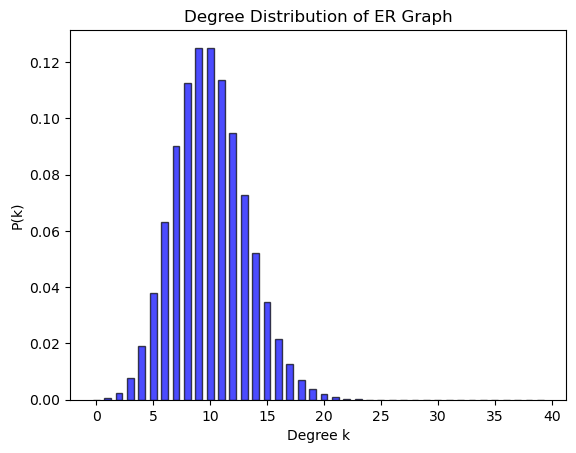

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# 参数
N = 1000
p = 0.01
lambda_ = p * N

# 计算度分布
k_values = np.arange(0, 40)  # 度的可能取值范围
P_k = poisson.pmf(k_values, lambda_)

# 绘制度分布
plt.bar(k_values, P_k, width=0.6, color='blue', alpha=0.7, edgecolor='black')
plt.xlabel('Degree k')
plt.ylabel('P(k)')
plt.title('Degree Distribution of ER Graph')
plt.show()
